# Análisis ConnectaTel

Como **analista de datos**, tu objetivo es evaluar el **comportamiento de los clientes** de una empresa de telecomunicaciones en Latinoamérica, ConnectaTel. 

Trabajaremos con información registrada **hasta el año 2024**, lo cual permitirá analizar el comportamiento del negocio dentro de ese periodo.

Para ello trabajarás con tres datasets:  

- **plans.csv** → información de los planes actuales (precio, minutos incluidos, GB incluidos, costo por extra)  
- **users.csv** → información de los clientes (edad, ciudad, fecha de registro, plan, churn)  
- **usage.csv** → detalle del **uso real** de los servicios (llamadas y mensajes)  

Deberás **explorar**, **limpiar** y **analizar** estos datos para construir un **perfil estadístico** de los clientes, detectar **comportamientos atípicos** y crear **segmentos de clientes**.  

Este análisis te permitirá **identificar patrones de consumo**, **diseñar estrategias de retención** y **sugerir mejoras en los planes** ofrecidos por la empresa.

> 💡 Antes de empezar, recuerda pensar de forma **programática**: ¿qué pasos necesitas? ¿En qué orden? ¿Qué quieres medir y por qué?


--- 
## 🧩 Paso 1: Cargar y explorar

Antes de limpiar o combinar los datos, es necesario **familiarizarte con la estructura de los tres datasets**.  
En esta etapa, validarás que los archivos se carguen correctamente, conocerás sus columnas y tipos de datos, y detectarás posibles inconsistencias.

### 1.1 Carga de datos y vista rápida

**🎯 Objetivo:**  
Tener los **3 datasets listos en memoria**, entender su contenido y realizar una revisión preliminar.

**Instrucciones:**  
- Importa las librerías necesarias (por ejemplo `pandas`, `seaborn`, `matplotlib.pyplot`)
- Carga los archivos CSV usando `pd.read_csv()`:
  - **`/datasets/plans.csv`**  
  - **`/datasets/users_latam.csv`**  
  - **`/datasets/usage.csv`**  
- Guarda los DataFrames en las variables: `plans`, `users`, `usage`.  
- Muestra las primeras filas de cada DataFrame usando `.head()`.


In [21]:

# importar librerías

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import numpy as np

In [22]:
# cargar archivos
plans = pd.read_csv('/datasets/plans.csv')
users = pd.read_csv("/datasets/users_latam.csv")
usage = pd.read_csv("/datasets/usage.csv")

In [23]:
# mostrar las primeras 5 filas de plans

plans.head()

,plan_name,messages_included,gb_per_month,minutes_included,usd_monthly_pay,usd_per_gb,usd_per_message,usd_per_minute
0,Basico,100,5,100,12,1.2,0.08,0.10
1,Premium,500,20,600,25,1.0,0.05,0.07


In [24]:
# mostrar las primeras 5 filas de users

users.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date
0,10000,Carlos,Garcia,38,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN
1,10001,Mateo,Torres,53,?,2022-01-01 06:34:17.914478619,Basico,NaN
2,10002,Sofia,Ramirez,57,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN
3,10003,Mateo,Ramirez,69,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN
4,10004,Mateo,Torres,63,GDL,2022-01-02 02:17:11.657914478,Basico,NaN


In [25]:
# mostrar las primeras 5 filas de usage

usage.head()

,id,user_id,type,date,duration,length
0,1,10332,call,2024-01-01 00:00:00.000000000,0.09,NaN
1,2,11458,text,2024-01-01 00:06:30.969774244,NaN,39.0
2,3,11777,text,2024-01-01 00:13:01.939548488,NaN,36.0
3,4,10682,call,2024-01-01 00:19:32.909322733,1.53,NaN
4,5,12742,call,2024-01-01 00:26:03.879096977,4.84,NaN


**Tip:** Si no usas `print()` la tabla se vera mejor.

### 1.2 Exploración de la estructura de los datasets

**🎯 Objetivo:**  
Conocer la **estructura de cada dataset**, revisar cuántas filas y columnas tienen, identificar los **tipos de datos** de cada columna y detectar posibles **inconsistencias o valores nulos** antes de iniciar el análisis.

**Instrucciones:**  
- Revisa el **número de filas y columnas** de cada dataset usando `.shape`.  
- Usa `.info()` en cada DataFrame para obtener un **resumen completo** de columnas, tipos de datos y valores no nulos.  

In [26]:
# revisar el número de filas y columnas de cada dataset
print("plans", plans.shape)
print("users", users.shape)
print("usage", usage.shape)

plans (2, 8)
users (4000, 8)
usage (40000, 6)


In [27]:
# inspección de plans con .info()
plans.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   plan_name          2 non-null      object 
 1   messages_included  2 non-null      int64  
 2   gb_per_month       2 non-null      int64  
 3   minutes_included   2 non-null      int64  
 4   usd_monthly_pay    2 non-null      int64  
 5   usd_per_gb         2 non-null      float64
 6   usd_per_message    2 non-null      float64
 7   usd_per_minute     2 non-null      float64
dtypes: float64(3), int64(4), object(1)
memory usage: 256.0+ bytes


In [28]:
# inspección de users con .info()
users.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   user_id     4000 non-null   int64 
 1   first_name  4000 non-null   object
 2   last_name   4000 non-null   object
 3   age         4000 non-null   int64 
 4   city        3531 non-null   object
 5   reg_date    4000 non-null   object
 6   plan        4000 non-null   object
 7   churn_date  466 non-null    object
dtypes: int64(2), object(6)
memory usage: 250.1+ KB


In [29]:
# inspección de usage con .info()
usage.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        40000 non-null  int64  
 1   user_id   40000 non-null  int64  
 2   type      40000 non-null  object 
 3   date      39950 non-null  object 
 4   duration  17924 non-null  float64
 5   length    22104 non-null  float64
dtypes: float64(2), int64(2), object(2)
memory usage: 1.8+ MB


---

## 🧩Paso 2: Identificación de problemas de calidad de datos

### 2.1 Revisión de valores nulos

**🎯 Objetivo:**  
Detectar la presencia y magnitud de valores faltantes para evaluar si afectan el análisis o requieren imputación/eliminación.

**Instrucciones:**  
- Cuenta valores nulos por columna para cada dataset.
- Calcula la proporción de nulos por columna para cada dataset.

El dataset `plans` solamente tiene 2 renglones y se puede observar que no tiene ausentes, por ello no necesita exploración adicional.

<br>
<details>
<summary>Haz clic para ver la pista</summary>
Usa `.isna().sum()` para contar valores nulos y usa `.isna().mean()` para calcular la proporción.

In [30]:
# cantidad de nulos para users
print(users.isna().sum())
print(users.isna().mean())

user_id          0
first_name       0
last_name        0
age              0
city           469
reg_date         0
plan             0
churn_date    3534
dtype: int64
user_id       0.00000
first_name    0.00000
last_name     0.00000
age           0.00000
city          0.11725
reg_date      0.00000
plan          0.00000
churn_date    0.88350
dtype: float64


In [31]:
# cantidad de nulos para usage
print(usage.isna().sum())
print(usage.isna().mean())

id              0
user_id         0
type            0
date           50
duration    22076
length      17896
dtype: int64
id          0.00000
user_id     0.00000
type        0.00000
date        0.00125
duration    0.55190
length      0.44740
dtype: float64


✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico al final del bloque. Incluye qué ves y que acción recomendarías para cada caso.

💡 **Nota:** Justifica tus decisiones brevemente (1 línea por caso).
* Hint:
 - Si una columna tiene **más del 80–90% de nulos**, normalmente se **ignora o elimina**.  
 - Si tiene **entre 5% y 30%**, generalmente se **investiga para imputar o dejar como nulos**.  
 - Si es **menor al 5%**, suele ser un caso simple de imputación o dejar como nulos. 
 
 ---

**Valores nulos**  
- 
En cuanto a los valores faltantes, en la tabla users la columna city presenta un 11.7% de nulos que se planea investigar e imputar de ser posible, mientras que churn_date cuenta con un elevado 88.35% de nulos que se mantendrán como tal, ya que reflejan de manera natural a los usuarios que aún no han cancelado el servicio. Por su parte, en la tabla usage, la columna date muestra un mínimo de 0.125% de nulos aptos para su imputación, en contraste con duration (55.19%) y length (44.74%), las cuales se conservarán vacías debido a su naturaleza estructural, dado que la duración aplica exclusivamente a las llamadas y la longitud únicamente a los mensajes de texto.

### 2.2 Detección de valores inválidos y sentinels

🎯 **Objetivo:**  
Identificar sentinels: valores que no deberían estar en el dataset.

**Instrucciones:**
- Explora las columnas numéricas con **un resumen estadístico** y describe brevemente que encontraste.
- Explora las columnas categóricas **relevantes**, revisando sus valores únicos y describe brevemente que encontraste.


El dataset `plans` solamente tiene 2 renglones, por ello no necesita exploración adicional.

In [32]:
# explorar columnas numéricas de users
print(users['age'].describe())

count    4000.000000
mean       33.739750
std       123.232257
min      -999.000000
25%        32.000000
50%        47.000000
75%        63.000000
max        79.000000
Name: age, dtype: float64


In [33]:
# contar cuántos usuarios tienen age= -999
condition=users['age']==-999
print(condition.sum())

55


- La columna `user_id` es un identificador único de cada usuario por lo que se asume que no presenta duplicados por su función como ID.
- La columna `age` muestra 55 registros con el valor atipico de -999, mientras que el resto de las edades se encuentran en un rango razonable hasta de 79 años, por lo que deben tratarse estos datos érroneos antes del análisis.

In [34]:
# explorar columnas numéricas de usage
print(usage.describe())

                id       user_id      duration        length
count  40000.00000  40000.000000  17924.000000  22104.000000
mean   20000.50000  12002.405975      5.202237     52.127398
std    11547.14972   1157.279564      6.842701     56.611183
min        1.00000  10000.000000      0.000000      0.000000
25%    10000.75000  10996.000000      1.437500     37.000000
50%    20000.50000  12013.000000      3.500000     50.000000
75%    30000.25000  13005.000000      6.990000     64.000000
max    40000.00000  13999.000000    120.000000   1490.000000


- Las columnas `id` y `user_id` tienen 40.000 regsitros, id va desde 1 a 40.000 y sus valores son únicos, por lo que identifica cada registro. user_id va de 10.000 a 13.999; el rango contiene 4.000 registros pero hay 3.999 valores únicos, lo que indica que falta un user_id dentro de este rango. 
- Las columnas duration y length presentan valores nulos, pero esto se debe al tipo de registro. duration solo corresponde a las llamadas, mientras lenght solo corresponde a los mensajes, por lo tanto los valores ausentes en estas columnas son esperados y no necesariamente representan errores de los datos. 

In [35]:
# explorar columna categórica de users
columnas_user = ['city','plan']
for city in columnas_user:
    print(users[city].value_counts())

Bogotá      808
CDMX        730
Medellín    616
GDL         450
Cali        424
MTY         407
?            96
Name: city, dtype: int64
Basico     2595
Premium    1405
Name: plan, dtype: int64


In [36]:
# explorar columna categórica de usage
usage['type'].value_counts()

text    22092
call    17908
Name: type, dtype: int64

- La columna `type` contiene dos categoria text con 22092 y call con 17.908 registros. No se identifican valores sentinels ni categorias sospechosas en esta columna.


---
✍️**Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico. Incluye qué ves y que acción recomendarías para cada caso. 

**Valores inválidos o sentinels**  
- ¿En qué columnas encontraste valores inválidos o sentinels?  
¿Qué acción tomarías?

- En la columna `age` se encontraron 55 registros con el valor `-999`, que no corresponde a una edad válida. Se recomienda reemplazar estos valores por `NaN` para tratarlos como datos faltantes. 
- En la columna `city` se encontraron 96 registros con el valor `?`, que representa una cantidad desconocida. Se recomienda reemplazar estos valores por `NaN` para tratarlos como datos faltantes.
- En las columnas `plan` y `type` no se encontraron valores inválidos o sentinels, ambas contiene categorias validas.
- Las columnas `id` y `user_id` no presentan inconsistencias, `id` es unico para cada registro, mientras que `user_id` puede repetirse porque un usiuario puede tener varios registros de uso.

### 2.3 Revisión y estandarización de fechas

**🎯 Objetivo:**  
Asegurar que las columnas de fecha estén correctamente formateadas y detectar años fuera de rango que indiquen errores de captura.

**Instrucciones:**  
- Convierte las columnas de fecha a tipo fecha y asegurate de que el código sea a prueba de errores.  
- Revisa cuántas veces aparece cada año.
- Identifica fechas imposibles (ej. años futuros o negativos).

Toma en cuenta que tenemos datos registrados hasta el año 2024.

In [37]:
# Convertir a fecha la columna `reg_date` de users
users['reg_date'] = pd.to_datetime(users['reg_date'],errors='coerce')

In [38]:
# Convertir a fecha la columna `date` de usage
usage['date'] = pd.to_datetime(usage['date'],errors='coerce')

In [39]:

# Revisar los años presentes en `reg_date` de users
users['reg_date'].dt.year.value_counts()


2024    1330
2023    1316
2022    1314
2026      40
Name: reg_date, dtype: int64

En `reg_date`, se observa consistencia historica entre el año 2022 al año 2024, esto puede evidenciar que la base de datos crecia a un ritmo muy estable y predecible durante esos tres años. Sin embargo hay 40 registros para el año 2026 que resultan atipicos puesto que los datos de los registros se recolectaron hasta el año 2024, estos registros pueden ser fechas erroneas, datos de otra fuente que se mezclaron en algun momento del proceso, entre otras causas. 

In [40]:

# Revisar los años presentes en `date` de usage
usage['date'].dt.year.value_counts()


2024.0    39950
Name: date, dtype: int64

En `date`, surgen hallazgos que son importantes constrastar con el comportamiento del dataset de users, a diferencia de la tabla users que abarca desde 2022 hasta 2024 el DataFrame usage cuenta con 39.950 registros concentrados exclusivamente en el ano 2024, por lo cual se puede concluir que el registro de uso o actividad no posee trazabilidad historia para los usuarios creados en 2022 o 2023, o bien solo se recopilo informacion de actividad para el ano 2024. 

✍️**Comentario**: escribe tu diagnóstico, e incluye **qué acción recomendarías** para cada caso:

**Fechas fuera de rango**  
- ¿Aparecen años imposibles? (años muy viejos o sin transcurrir al momento de guardar los datos)
- ¿Qué harías con ellas?

Diagnóstico General de Fechas: 

1.Tabla users: Registros con años fuera de rango (2026), se identificarón 40 registros fechados en 2026 en un dataset cuya recoleccion finalizo oficialmente en 2024. 
Acción recomendada: Filtrar los 40 registros para ver si comparten patrones como mismos IDs, estado de cuenta o comportmientos, si no hay forma de validar su fecha real de creacion, lo mas seguro para la integridad del analisis es eliminarlos o reclasificarlos como nulos o valores atipicos ya que falsean las metricas de creicmiento de 2024 en adelante.

2.Tabla Usage:  Valores nulos implicitos. El formato númerico con decimales (2024.0), al extraer el año evidencia la existencia de valores nulos (NaN) en la columna date (exactamente 50 registros, lo que representa un 0.1255% del total). Asimismo, el dataset de uso se encuentra acotado exclusivamente al año 2024, sin trazabilidad histórica previa. 
Acción recomendada: Dado que el porcentaje de nulos es extremadamente bajo (0,125%), se recomienda eliminar esas 50 filas o imputarlas de manera coherente con la estrategia definida en la sección 2.1 para no sesgar las métricas de uso diario o mensual.  

---

## 🧩Paso 3: Limpieza básica de datos

### 3.1 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Aplicar reglas de limpieza para reemplazar valores sentinels y corregir fechas imposibles.

**Instrucciones:**  
- En `age`, reemplaza el sentinel **-999** con la mediana.
- En `city`, reemplaza el sentinel `"?"` por valores nulos (`pd.NA`).  
- Marca como nulas (`pd.NA`) las fechas fuera de rango.

In [41]:
# Reemplazar -999 por la mediana de age
age_mediana = users['age'].median()
users['age'] = users['age'].replace(-999,np.nan)
users['age'] = users['age'].fillna(age_mediana)

# Verificar cambios
users['age'].describe()

count    4000.000000
mean       48.122250
std        17.690408
min        18.000000
25%        33.000000
50%        47.000000
75%        63.000000
max        79.000000
Name: age, dtype: float64

In [42]:
# Reemplazar ? por NA en city
users['city'] = users['city'].replace('?',np.nan)
users = users.dropna(subset=['city'])

# Verificar cambios
users['city'].isna().sum()



0

### 3.2 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Decidir qué hacer con los valores nulos según su proporción y relevancia.

**Instrucciones:**
- Verifica si los nulos en `duration` y `length` son **MAR**(Missing At Random) revisando si dependen de la columna `type`.  
  Si confirmas que son MAR, **déjalos como nulos** y justifica la decisión.

In [43]:


# Marcar fechas futuras como NA para reg_date
users.loc[users['reg_date']>= '2026-01-01','reg_date']=np.nan

# Verificar cambios
users['reg_date'].isna().sum()



37

In [44]:
# Verificación MAR en usage (Missing At Random) para duration
usage.loc[usage['duration'].isna(),'type'].value_counts()


text    22076
Name: type, dtype: int64

In [45]:
# Verificación MAR en usage (Missing At Random) para length
usage.loc[usage['length'].isna(),'type'].value_counts()


call    17896
Name: type, dtype: int64

**Analisis de Valores Nulos en duration y length**
1. Columna duration
Los 22,076 valores nulos encontrados en duration pertenecen a los registros donde type es 'text'. Este es un comportamiento completamente esperado ya que los mensajes de texto (text) no tienen "duración" en el tiempo (a diferencia de las llamadas), por lo que es natural que este campo esté vacío.
2. Columna length
Los 17,896 valores nulos encontrados en length pertenecen a los registros donde type es 'call'. Al igual que en el caso anterior, se debe a que las llamadas (call) no tienen una "longitud" de caracteres (que típicamente mide el tamaño de un mensaje de texto), por lo que el campo queda vacío para este tipo de evento.

En ambos casos no se esta representando una pérdida de datos ni un error de recolección aleatorio. Se trata de datos faltantes estructurales, donde las columnas duration y length son mutuamente excluyentes y dependen directamente de la categoría del evento (type: llamada vs. texto).

Se Recomienda no eliminar ni imputar con ceros: No se deben borrar estas filas ni rellenar los nulos con ceros o medias estadísticas, ya que distorsionaría el significado de las métricas. Se deben mantener los valores como NaN y reconocer que cada métrica aplica exclusivamente a su respectivo tipo de interacción (duration para llamadas y length para textos).

---

## 🧩Paso 4: Summary statistics de uso por usuario


### 4.1 Agrupación por comportamiento de uso

🎯**Objetivo**: 
Resumir las variables clave de la tabla `usage` **por usuario**, creando métricas que representen su comportamiento real de uso histórico. 

**Instrucciones:**: 
1. Construye una tabla agregada de `usage` por `user_id` que incluya:
- número total de mensajes  
- número total de llamadas  
- total de minutos de llamadas

2. Renombra las columnas para que tengan nombres claros:  
- `cant_mensajes`  
- `cant_llamadas`  
- `cant_minutos_llamada`
3. Combina esta tabla con `users`.


In [46]:
usage['type'].unique()

array(['call', 'text'], dtype=object)

In [47]:
# Columnas auxiliares
usage["is_text"] = (usage["type"] == "text").astype(int) #conocer el total de mensajes
usage["is_call"] = (usage["type"] == "call").astype(int) #conocer el total de llamadas


# Agrupar información por usuario
usage_agg = usage.groupby('user_id').agg({'is_call': 'sum', 'is_text':'sum','duration':'sum'}).reset_index()

# observar resultado
usage_agg.head(3)

,user_id,is_call,is_text,duration
0,10000,3,7,23.70
1,10001,10,5,33.18
2,10002,2,5,10.74


In [48]:
# Renombrar columnas
usage_agg=usage_agg.rename(columns={'is_call': 'cant_llamadas','is_text': 'cant_mensajes','duration': 'cant_minutos_llamada'})

# observar resultado
usage_agg.head(3)

,user_id,cant_llamadas,cant_mensajes,cant_minutos_llamada
0,10000,3,7,23.70
1,10001,10,5,33.18
2,10002,2,5,10.74


In [49]:
# Combinar la tabla agregada con el dataset de usuarios
user_profile =users.merge(usage_agg, on='user_id')
user_profile.head(5)

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_llamadas,cant_mensajes,cant_minutos_llamada
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,3,7,23.70
1,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,2,5,10.74
2,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,3,11,8.99
3,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,3,4,8.01
4,10005,Luis,Garcia,61.0,MTY,2022-01-02 08:51:29.572393098,Basico,NaN,7,5,44.97


### 4.2 4.2 Resumen estadístico por usuario durante el 2024

🎯 **Objetivo:** Analizar las columnas numéricas y categóricas de los usuarios, para identificar rangos, valores extremos y distribución de los datos antes de continuar con el análisis.

**Instrucciones:**  
1. Para las columnas **numéricas** relevantes, obtén un resumen estadístico (media, mediana, mínimo, máximo, etc.).  
2. Para la columna **categórica** `plan`, revisa la distribución en **porcentajes** de cada categoría.

In [50]:
# Resumen estadístico de las columnas numéricas
resumen_estadistico=user_profile[['cant_llamadas','cant_mensajes','cant_minutos_llamada']].describe()
resumen_estadistico

,cant_llamadas,cant_mensajes,cant_minutos_llamada
count,3434.000000,3434.000000,3434.000000
mean,4.478451,5.513104,23.428987
std,2.145787,2.336273,18.409015
min,0.000000,0.000000,0.000000
25%,3.000000,4.000000,11.115000
50%,4.000000,5.000000,19.845000
75%,6.000000,7.000000,31.495000
max,15.000000,17.000000,155.690000


In [51]:
# Distribución porcentual del tipo de plan
distribution_plan=user_profile['plan'].value_counts(normalize=True)
distribution_plan

Basico     0.648806
Premium    0.351194
Name: plan, dtype: float64

---

## 🧩Paso 5: Visualización de distribuciones (uso y clientes) y outliers


### 5.1 Visualización de Distribuciones

🎯 **Objetivo:**  
Entender visualmente cómo se comportan las variables clave tanto de **uso** como de **clientes**, observar si existen diferencias según el tipo de plan, y analizar la **forma de la distribución**.

**Instrucciones:**  
Graficar **histogramas** para las siguientes columnas:  
- `age` (edad de los usuarios)
- `cant_mensajes`
- `cant_llamadas`
- `total_minutos_llamada` 

Después de cada gráfico, escribe un **insight** respecto al plan y la variable, por ejemplo:  
- "Dentro del plan Premium, hay mayor proporción de..."  
- "Los usuarios Básico tienden a hacer ... llamadas y enviar ... mensajes."  o "No existe algún patrón."
- ¿Qué tipo de distribución tiene ? (simétrica, sesgada a la derecha o a la izquierda) 

**Hint**  
Para cada histograma, 
- Usa `hue='plan'` para ver cómo varían las distribuciones según el plan (Básico o Premium).
- Usa `palette=['skyblue','green']`
- Agrega título y etiquetas

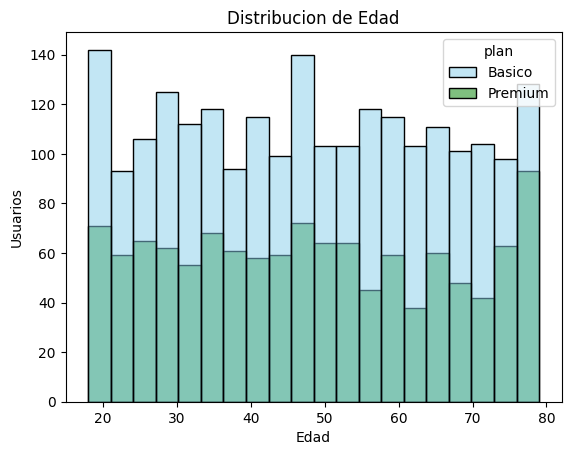

In [52]:
# Histograma para visualizar la edad (age)
sns.histplot(data=user_profile, x='age', bins=20, hue='plan', palette=['skyblue','green'])
plt.title('Distribucion de Edad')
plt.xlabel('Edad')
plt.ylabel('Usuarios')
plt.show()

💡Insights: 
- Distribución uniforme que evidencia que los usuarios no se concentran en un único rango de edad específico, se encuentran distribuidos de manera pareja y horizontal a lo largo de todo el espectro (desde los 20 hasta los 80 años), sin que ningún grupo de edad en específico destaque sobre los demás Por otro lado, al comparar los colores de los planes, se nota que tanto el Básico como el Premium se mezclan por igual en todas las edades, lo que significa que la edad de las personas no determina el tipo de plan que prefieren. 

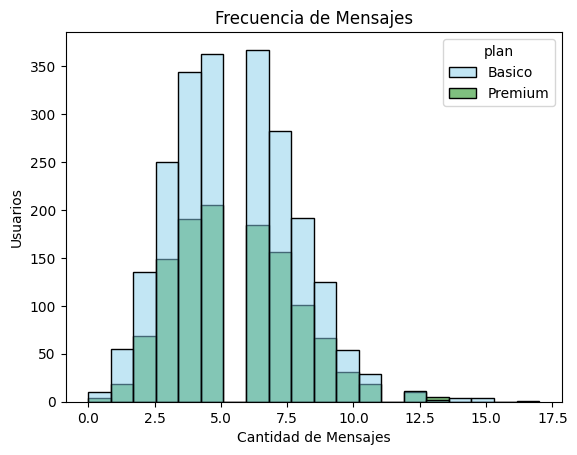

In [53]:

# Histograma para visualizar la cant_mensajes
sns.histplot(data=user_profile, x='cant_mensajes', bins=20, hue='plan', palette=['skyblue','green'])
plt.title('Frecuencia de Mensajes')
plt.xlabel('Cantidad de Mensajes')
plt.ylabel('Usuarios')
plt.show()



💡Insights: 
- El gráfico muestra que la cantidad de mensajes se concentra principalmente entre 3 y 8 por usuario, formando una distribución que sube y baja de manera similar a una campana. Asimismo, los planes Básico y Premium se reparten de forma muy parecida en todos los niveles de mensajes, lo que indica que el tipo de plan no influye de manera notable en cuántos mensajes envían los usuarios.

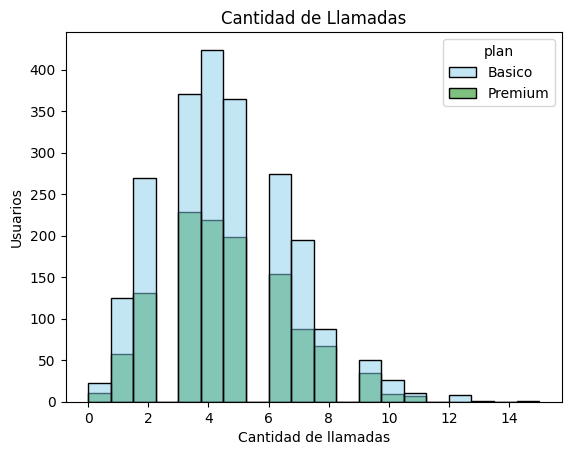

In [54]:
# Histograma para visualizar la cant_llamadas
sns.histplot(data=user_profile, x='cant_llamadas', bins=20, hue='plan', palette=['skyblue','green'])
plt.title('Cantidad de Llamadas')
plt.xlabel('Cantidad de llamadas')
plt.ylabel('Usuarios')
plt.show()

💡Insights: 
- El gráfico muestra que la cantidad de llamadas se concentra principalmente entre 3 y 6 llamadas por usuario, formando una distribución que sube y baja de manera parecida a una campana. Asimismo, los planes Básico y Premium se reparten de forma muy uniforme en todos los niveles de llamadas, lo que indica que el tipo de plan no determina cuántas llamadas realizan los usuarios

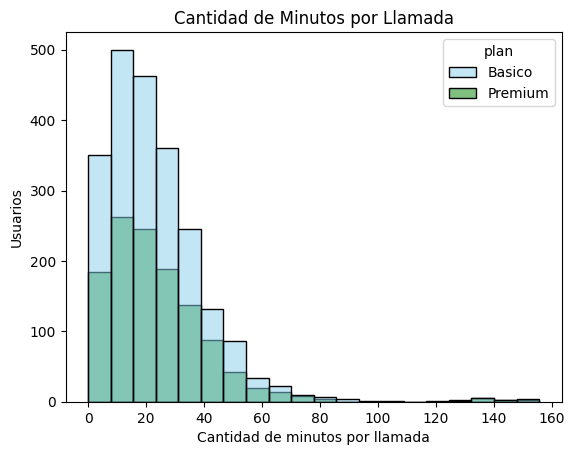

In [55]:
# Histograma para visualizar la cant_minutos_llamada
sns.histplot(data=user_profile, x='cant_minutos_llamada', bins=20, hue='plan', palette=['skyblue','green'])
plt.title('Cantidad de Minutos por Llamada')
plt.xlabel('Cantidad de minutos por llamada')
plt.ylabel('Usuarios')
plt.show()


💡Insights: 
- El gráfico muestra que la cantidad de minutos de llamada se concentra principalmente en los valores más bajos, entre 0 y 30 minutos por usuario, presentando una distribución sesgada hacia la derecha con una disminución gradual a medida que aumentan los minutos. Asimismo, los planes Básico y Premium se distribuyen de manera muy similar en todos los niveles, lo que indica que el tipo de plan no determina la cantidad de minutos que consumen los usuarios.

### 5.2 Identificación de Outliers

🎯 **Objetivo:**  
Detectar valores extremos en las variables clave de **uso** y **clientes** que podrían afectar el análisis, y decidir si requieren limpieza o revisión adicional.

**Instrucciones:**  
- Usa **boxplots** para identificar visualmente outliers en las siguientes columnas:  
  - `age` 
  - `cant_mensajes`
  - `cant_llamadas`
  - `total_minutos_llamada`  
- Crea un **for** para generar los 4 boxplots automáticamente.
<br>

- Después de crear los gráfico, responde si **existen o no outliers** en las variables.  
- Si hay outliers, crea otro bucle para calcular los límites de esas columnas usando el **método IQR** y decide qué hacer con ellos.
  - Si solamente hay outliers de un solo lado, no es necesario calcular ambos límites.

**Hint:**
- Dentro del bucle, usa `plt.title(f'Boxplot: {col}')` para que el título cambie acorde a la columna.

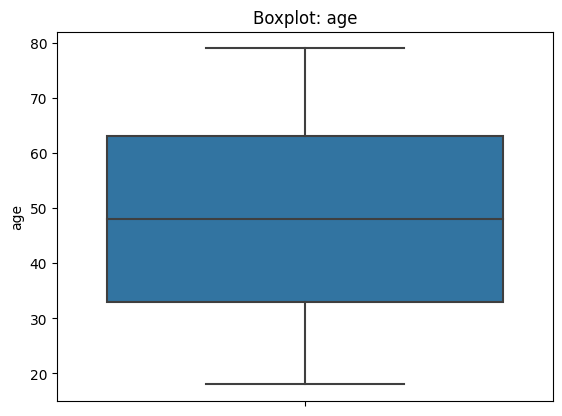

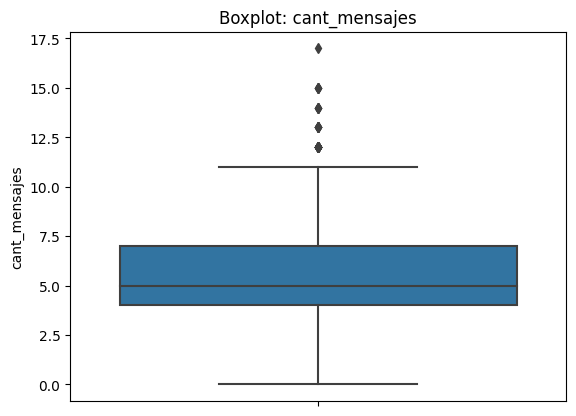

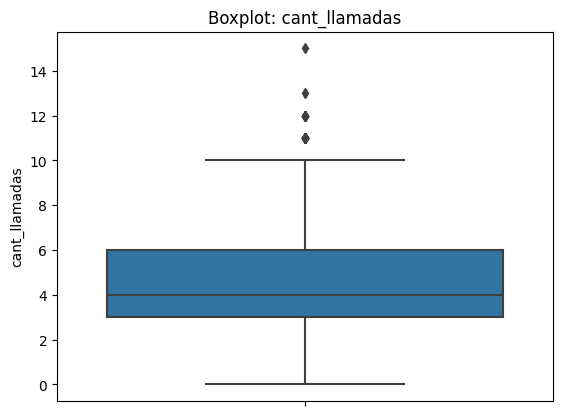

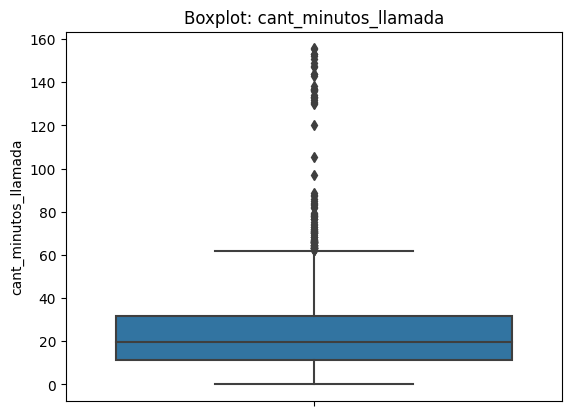

In [56]:
# Visualizando usando BoxPlot 
columnas_numericas = ['age', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']

for columna_numerica in columnas_numericas:


    
    sns.boxplot(data=user_profile, y=columna_numerica)
    plt.title(f'Boxplot: {columna_numerica}')
    plt.show()

💡Insights: 
- Age: El gráfico muestra que las edades de los usuarios están distribuidas entre los 18 y los 80 años, con la mitad de las personas ubicándose aproximadamente entre los 34 y los 64 años. La línea del centro marca una edad promedio de unos 48 años. No se ven valores atípicos (puntos aislados), lo que indica que las edades son coherentes y logicos para los usuarios del servicio.
- cant_mensajes: La mayoría de los usuarios envía entre 4 y 7 mensajes, situándose la mitad central en ese rango. Sin embargo, en la parte superior se observan varios puntos aislados (valores atípicos) que van desde los 12 hasta casi los 18 mensajes. Esto indica que existen algunos usuarios que envian bastantes más mensajes que el promedio general de la plataforma.
- cant_llamadas: El centro de los datos se concentra entre 3 y 6 llamadas por usuario, con una mediana en 4 llamadas. También aparecen unos cuantos valores atípicos en la parte alta (entre 11 y 15 llamadas), lo que representa a ese pequeño grupo de usuarios que realiza llamadas con mucha más frecuencia que el resto.
- cant_minutos_llamada: Aquí la mitad de los usuarios consume entre aproximadamente 12 y 35 minutos en total, con un punto medio en los 20 minutos. No obstante, el gráfico cuenta con una larga fila de puntos atípicos hacia arriba que superan los 60 minutos y alcanzan picos de hasta casi 160 minutos. Esto refleja la presencia de usuarios con un consumo de llamadas sumamente alto en comparación con la tendencia común.

In [57]:
# Calcular límites con el método IQR
columnas_limites = ['cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']

Q1_mensajes = user_profile['cant_mensajes'].quantile(0.25)
Q3_mensajes = user_profile['cant_mensajes'].quantile(0.75)
IQR_mensajes = Q3_mensajes - Q1_mensajes
limite_superior_mensajes = Q3_mensajes + 1.5 * IQR_mensajes

Q1_llamadas = user_profile['cant_llamadas'].quantile(0.25)
Q3_llamadas = user_profile['cant_llamadas'].quantile(0.75)
IQR_llamadas = Q3_llamadas - Q1_llamadas
limite_superior_llamadas = Q3_llamadas + 1.5 * IQR_llamadas

Q1_cant_minutos_llamada = user_profile['cant_minutos_llamada'].quantile(0.25)
Q3_cant_minutos_llamada = user_profile['cant_minutos_llamada'].quantile(0.75)
IQR_cant_minutos_llamada = Q3_cant_minutos_llamada - Q1_cant_minutos_llamada
limite_superior_cant_minutos_llamada = Q3_cant_minutos_llamada + 1.5 * IQR_cant_minutos_llamada

print("Límite superior mensajes:", limite_superior_mensajes, "Límite superior llamadas:", limite_superior_llamadas, "Límite superior cant minutos llamada:", limite_superior_cant_minutos_llamada)

Límite superior mensajes: 11.5 Límite superior llamadas: 10.5 Límite superior cant minutos llamada: 62.065


In [58]:
# Revisa los limites superiores y el max, para tomar la decisión de mantener los outliers o no
user_profile[columnas_limites].describe()

,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,3434.000000,3434.000000,3434.000000
mean,5.513104,4.478451,23.428987
std,2.336273,2.145787,18.409015
min,0.000000,0.000000,0.000000
25%,4.000000,3.000000,11.115000
50%,5.000000,4.000000,19.845000
75%,7.000000,6.000000,31.495000
max,17.000000,15.000000,155.690000


💡Insights: 
- cant_mensajes: Se sugiere mantener los outliers, aunque superan el limite superior estadistico (11.5) llegando hasta 17 mensajes, son valores logicos en la vida real. Eliminar estos datos significaria ignorar el segmento mas participativo de la plataforma y esto distorsionaria cualquier análisis sobre el comportamiento real de los usuarios. 
- cant_llamadas: Se sugiere mantener los outliers los valores entre 11 y 15 llamadas están por encima del limitte (10.5), pero son datos posibles para un usuario que usa el servicio teléfonico con alta frecuencia, no mantenerlos significaria perder información sobre este grupo de usuarios activos. 
- cant_minutos_llamada: Se sugiere mantener los outliers aunque hay una dispersión grande que llega hasta los 155 minutos (cuando el límite superior es 62), esto es muy común en las telecomunicaciones: siempre habrá un grupo reducido de personas que habla mucho más tiempo que el resto. Si se eliminan, se ocultarían perfiles de consumo clave que podrían ser fundamentales para diferenciar planes (por ejemplo, Básico vs. Premium).

---

## 🧩Paso 6: Segmentación de Clientes

### 6.1 Segmentación de Clientes Por Uso

🎯 **Objetivo:** Clasificar a cada usuario en un grupo de uso (Bajo uso, Uso medio, Alto uso) basándose en la cantidad de llamadas y mensajes registrados.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_uso` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones de llamadas y mensajes y asigna:
  - `'Bajo uso'` cuando llamadas < 5 y mensajes < 5
  - `'Uso medio'` cuando llamadas < 10 y mensajes < 10
  - `'Alto uso'` para el resto de casos

In [59]:
# Crear columna grupo_uso
def clasificar_uso(fila):
    if fila['cant_llamadas']<5 and fila['cant_mensajes']  < 5:
        return 'Bajo uso'
    elif fila['cant_llamadas']<10 and  fila['cant_mensajes'] < 10:
        return 'Uso medio'
    else:
        return 'Alto uso'

user_profile['grupo_uso'] = user_profile.apply(clasificar_uso, axis=1)

In [60]:
# verificar cambios
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_llamadas,cant_mensajes,cant_minutos_llamada,grupo_uso
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,3,7,23.70,Uso medio
1,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,2,5,10.74,Uso medio
2,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,3,11,8.99,Alto uso
3,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,3,4,8.01,Bajo uso
4,10005,Luis,Garcia,61.0,MTY,2022-01-02 08:51:29.572393098,Basico,NaN,7,5,44.97,Uso medio


### 6.2 Segmentación de Clientes Por Edad

🎯 **Objetivo:**: Clasificar a cada usuario en un grupo por **edad**.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_edad` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones y asigna:
  - `'Joven'` cuando age < 30
  - `'Adulto'` cuando age < 60
  - `'Adulto Mayor'` para el resto de casos

In [61]:
# Crear columna grupo_edad

def clasificar_edad(fila):
    if fila['age']<30:
        return 'Joven'
    elif fila['age']<60:
        return 'Adulto'
    else:
        return 'Adulto Mayor'

user_profile['grupo_edad'] = user_profile.apply(clasificar_edad, axis=1)

In [62]:
# verificar cambios
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_llamadas,cant_mensajes,cant_minutos_llamada,grupo_uso,grupo_edad
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,3,7,23.70,Uso medio,Adulto
1,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,2,5,10.74,Uso medio,Adulto
2,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,3,11,8.99,Alto uso,Adulto Mayor
3,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,3,4,8.01,Bajo uso,Adulto Mayor
4,10005,Luis,Garcia,61.0,MTY,2022-01-02 08:51:29.572393098,Basico,NaN,7,5,44.97,Uso medio,Adulto Mayor


### 6.3 Visualización de la Segmentación de Clientes

🎯 **Objetivo:** Visualizar la distribución de los usuarios según los grupos creados: **grupo_uso** y **grupo_edad**.

**Instrucciones:**  
- Crea dos gráficos para las variables categóricas `grupo_uso` y `grupo_edad`.
- Agrega título y etiquetas a los ejes en cada gráfico.

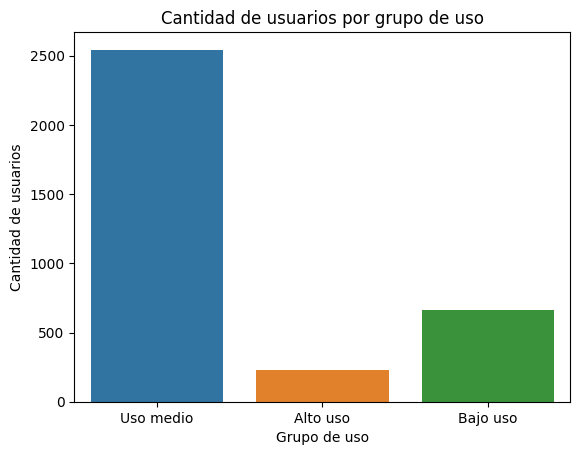

In [63]:
# Visualización de los segmentos por uso

sns.countplot(data=user_profile, x='grupo_uso')
plt.title('Cantidad de usuarios por grupo de uso')
plt.xlabel('Grupo de uso')
plt.ylabel('Cantidad de usuarios')
plt.show()

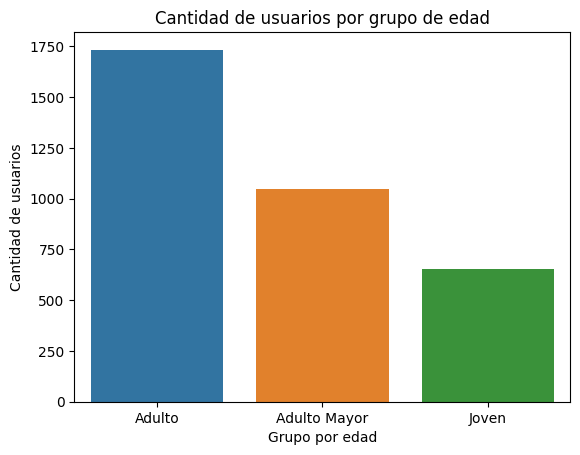

In [64]:
# Visualización de los segmentos por edad

sns.countplot(data=user_profile, x='grupo_edad')
plt.title('Cantidad de usuarios por grupo de edad')
plt.xlabel('Grupo por edad')
plt.ylabel('Cantidad de usuarios')
plt.show()


---
## 🧩Paso 7: Insight Ejecutivo para Stakeholders

🎯 **Objetivo:** Traducir los hallazgos del análisis en conclusiones accionables para el negocio, enfocadas en segmentación, patrones de uso y oportunidades comerciales.

**Preguntas a responder:** 
- ¿Qué problemas tenían originalmemte los datos?¿Qué porcentaje, o cantidad de filas, de esa columna representaban?


- ¿Qué segmentos de clientes identificaste y cómo se comportan según su edad y nivel de uso?  
- ¿Qué segmentos parecen más valiosos para ConnectaTel y por qué?  
- ¿Qué patrones de uso extremo (outliers) encontraste y qué implican para el negocio?


- ¿Qué recomendaciones harías para mejorar la oferta actual de planes o crear nuevos planes basados en los segmentos y patrones detectados?

✍️ **Escribe aquí tu análisis ejecutivo:**

In [68]:
user_profile['grupo_edad'].value_counts(normalize=True).mul(100).round(2)

Adulto          50.47
Adulto Mayor    30.46
Joven           19.07
Name: grupo_edad, dtype: float64

In [69]:
user_profile['grupo_uso'].value_counts(normalize=True).mul(100).round(2)

Uso medio    74.05
Bajo uso     19.31
Alto uso      6.64
Name: grupo_uso, dtype: float64

In [70]:
pd.crosstab(user_profile['grupo_edad'], user_profile['grupo_uso'], normalize='index').mul(100).round(2)

grupo_uso,Alto uso,Bajo uso,Uso medio
grupo_edad,,,
Adulto,7.33,17.66,75.01
Adulto Mayor,5.54,21.22,73.23
Joven,6.56,20.61,72.82


### Análisis ejecutivo

⚠️ **Problemas detectados en los datos**

En users, la columna city tenía 469 valores nulos (11,73 %) y 96 registros con ? (2,4 % de los 4.000 usuarios). Se sustituyó ? por nulo y se eliminaron los registros sin ciudad; por ello, los análisis de perfil corresponden a los usuarios restantes.
En users, age contenía 55 valores sentinels -999 (1,375 %), que se sustituyeron por la mediana. También se encontraron 40 fechas de registro de 2026 (1 %), marcadas como ausentes por estar fuera del periodo analizado.
En usage, faltaba date en 50 de 40.000 registros (0,125 %). También había valores ausentes en duration (22.076; 55,19 %) y length (17.896; 44,74 %). Estos últimos se deben interpretar según el tipo de interacción: la duración corresponde a llamadas y la longitud a mensajes, por lo que no todos esos nulos representan errores.


🔍 **Segmentos por Edad y por Nivel de Uso**

La tabla cruzada entre grupo de edad y nivel de uso muestra diferencias en el comportamiento de los usuarios. Los Adultos Mayores presentan el mayor porcentaje de usuarios de Bajo uso, con un 21,22%, y el menor porcentaje de usuarios de Alto uso, con un 5,54%. Esto indica que, dentro de la distribución analizada, este grupo tiene una mayor presencia relativa de usuarios con menor nivel de uso.

Por su parte, el grupo de Adultos registra el mayor porcentaje de usuarios de Alto uso, con un 7,33%, lo que lo convierte en un segmento interesante para estrategias de fidelización y promoción de planes que respondan a un consumo más intensivo.

Estos resultados permiten identificar diferencias entre los grupos de edad y orientar las estrategias comerciales: en los Adultos Mayores podría ser conveniente impulsar acciones para aumentar el uso de los servicios, mientras que en los Adultos se podrían evaluar oportunidades de fidelización y planes de mayor valor.

📊 **Segmentos Valiosos**

El segmento de clientes de Alto uso es un candidato importante para las estrategias comerciales, ya que agrupa a usuarios que realizan más llamadas o envían más mensajes que los demás. Aunque representa el 6,64 % de los usuarios analizados, podría ser una oportunidad para ofrecer planes con más minutos y mensajes incluidos, adaptados a sus necesidades de consumo.

Por edad, el grupo de Adultos presenta el mayor porcentaje de usuarios de Alto uso, con un 7,33 %, frente al 6,56 % de los Jóvenes y al 5,54 % de los Adultos Mayores. Esto permite considerar a los Adultos como un segmento interesante para evaluar estrategias de fidelización y ofertas ajustadas a un consumo más intensivo.

Sin embargo, estos resultados no demuestran por sí solos qué grupo genera mayores ganancias. Para identificar el segmento más rentable, ConnectaTel debería comparar los ingresos, los costos de servicio, la permanencia y la cancelación de los clientes, y analizar también su distribución entre los planes Básico y Premium.

📈 **Patrones de uso extremo (outliers) se encontraron e implicaciones.**

En el análisis mediante el método IQR se identificaron valores extremos en tres variables de uso:

Cantidad de mensajes: el límite superior fue de 11,5 mensajes y el máximo observado fue de 17.

Cantidad de llamadas: el límite superior fue de 10,5 llamadas y el máximo observado fue de 15.

Minutos de llamada: el límite superior fue de 62,065 minutos y el máximo observado fue de 155,69 minutos.

Estos valores representan usuarios cuyo consumo es considerablemente superior al de la mayoría. No necesariamente son errores: pueden corresponder a clientes que utilizan los servicios con mucha frecuencia. Por eso, se recomienda conservarlos mientras no se compruebe que son registros incorrectos.

Desde la perspectiva del negocio, estos patrones pueden ayudar a identificar oportunidades para ofrecer planes con mayor capacidad de llamadas y mensajes. No obstante, también conviene evaluar si el consumo elevado incrementa los costos de servicio. Revisar estos perfiles permitiría diseñar ofertas más adecuadas y tomar decisiones comerciales basadas en el comportamiento real de los clientes.


💡 **Recomendaciones**

Evaluar un plan para clientes de alto uso con más minutos y mensajes incluidos, verificando que el precio cubra los costos.

Probar paquetes flexibles o una alternativa económica para clientes de bajo uso, evitando que paguen por capacidad que no necesitan.

Usar las tablas cruzadas para segmentar campañas por edad, uso y plan. Priorizar la evaluación de clientes de alto uso con Premium y comparar su permanencia, ingresos y costos con otros grupos.

Revisar los outliers antes de tomar decisiones y mejorar la validación de datos, evitando valores sentinels como -999 y códigos como ?.

Documentar cuándo duration o length no aplican según el tipo de interacción, para distinguir valores ausentes esperados de errores reales.

---

## 🧩Paso 8 Cargar tu notebook y README a GitHub

🎯 **Objetivo:**  
Entregar tu análisis de forma **profesional**, **documentada** y **versionada**, asegurando que cualquier persona pueda revisar, ejecutar y entender tu trabajo.



### Opción A : Subir archivos desde la interfaz de GitHub (UI)

1. Descarga este notebook (`File → Download .ipynb`).  
2. Entra a tu repositorio en GitHub (por ejemplo `telecom-analysis` o `sprint7-final-project`).  
3. Sube tu notebook **Add file → Upload files**.  

---

### Opción B : Guardar directo desde Google Colab

1. Abre tu notebook en Colab.  
2. Ve a **File → Save a copy in GitHub**.  
3. Selecciona el repositorio y la carpeta correcta (ej: `notebooks/`).  
4. Escribe un mensaje de commit claro, por ejemplo:  
    - `feat: add final ConnectaTel analysis`
    - `agregar version final: Análisis ConnectaTel`
5. Verifica en GitHub que el archivo quedó en el lugar correcto y que el historial de commits se mantenga limpio.

---

Agrega un archivo `README.md` que describa de forma clara:
- el objetivo del proyecto,  
- los datasets utilizados,  
- las etapas del análisis realizadas,  
- cómo ejecutar el notebook (por ejemplo, abrirlo en Google Colab),  
- una breve guía de reproducción.
---

Link a repositorio público del proyecto: `LINK a tu repo aquí`